# 3. Out-of-Sample Validation & Challenger Analysis

## Objective

Evaluate the predictive performance of rolling volatility, EWMA, and GARCH(1,1) using a common out-of-sample test period.

This notebook compares the models using quantitative loss metrics, examines forecast errors across different volatility regimes, and assesses whether performance differences are statistically meaningful.

## Evaluation Framework

The analysis uses the 830 daily SPY return observations and the three variance forecasts generated in Notebook 02. Forecasts are evaluated on identical dates, using consistent variance units and one-day-ahead information timing.

The notebook covers:

- Forecast evaluation using mean squared error on squared returns and QLIKE.
- Comparison of forecast errors and volatility estimates over time.
- Performance across relatively calm and high-volatility periods.
- Statistical comparison of forecast losses, where appropriate.
- Model strengths, weaknesses, limitations, and a final recommendation.

## Scope

Model estimation, GARCH diagnostics, and forecast generation were completed in Notebooks 01 and 02. They will not be repeated here.

**The objective is to establish which approach provides the most useful volatility forecasts, based on out-of-sample evidence.**

## 1. Evaluation Metrics and Limitations

The target is squared daily SPY returns, $r_t^2$, which serves as a proxy for the unobserved daily variance. Each model's variance forecast is compared with this common target.

### Mean Squared Error (MSE)

$$
\mathrm{MSE} = \frac{1}{T} \sum_{t=1}^{T} (r_t^2 - \hat{\sigma}_t^2)^2
$$

MSE penalizes large forecast errors heavily. Consequently, a small number of extreme market movements can have a substantial influence on the result.

### Quasi-Likelihood Loss (QLIKE)

$$
\mathrm{QLIKE} = \frac{1}{T} \sum_{t=1}^{T} \left[ \log(\hat{\sigma}_t^2) + \frac{r_t^2}{\hat{\sigma}_t^2} \right]
$$

Lower QLIKE indicates better performance under this loss definition, provided all forecasts are strictly positive. QLIKE evaluates forecasts differently from MSE and provides a useful complementary comparison.

### Limitations

* Squared daily returns are a noisy proxy for actual realized variance; a single daily return does not reveal the full intraday variation in volatility.
* MSE is sensitive to extreme observations.
* Rankings can differ across loss functions because they penalize forecast errors differently.
* A lower average loss does not, by itself, establish that a model is statistically superior.

Both metrics will be calculated using decimal-return variance units and the same evaluation dates for all models.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parents[1]

### Load Forecasts from Notebook 02

Import the actual returns and aligned variance forecasts exported by Notebook 02. The original forecasts are retained without recalculation so that this notebook evaluates the same forecasting experiment.

In [2]:
FORECAST_PATH = (
    PROJECT_ROOT
    / "project_04_volatility_model_validation"
    / "data"
    / "processed"
    / "forecast_comparison.csv"
)

if not FORECAST_PATH.exists():
    raise FileNotFoundError(
        f"Forecast dataset not found: {FORECAST_PATH}\n"
        f"Current working directory: {Path.cwd()}"
    )

validation_data = pd.read_csv(
    FORECAST_PATH,
    parse_dates=["Date"],
    index_col="Date",
)

expected_columns = [
    "Actual_Return",
    "Rolling_Variance",
    "EWMA_Variance",
    "GARCH_Variance",
]

missing_columns = sorted(
    set(expected_columns) - set(validation_data.columns)
)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

validation_data = validation_data[expected_columns].sort_index()

print(f"Observations: {len(validation_data)}")
print(
    f"Evaluation period: {validation_data.index.min().date()} "
    f"to {validation_data.index.max().date()}"
)

validation_data.head()

Observations: 830
Evaluation period: 2022-09-12 to 2025-12-31


,Actual_Return,Rolling_Variance,EWMA_Variance,GARCH_Variance
Date,,,,
2022-09-12,0.010748,0.000180,0.000167,0.000153
2022-09-13,-0.043483,0.000179,0.000164,0.000141
2022-09-14,0.003816,0.000193,0.000268,0.000556
2022-09-15,-0.011353,0.000193,0.000252,0.000421
2022-09-16,-0.007629,0.000186,0.000245,0.000353


## 2. Out-of-Sample Forecast Scoring

Compare rolling volatility, EWMA, and GARCH(1,1) using mean squared error (MSE) on squared returns and QLIKE. Lower values indicate better performance for both metrics. Squared daily returns serve as a noisy proxy for the unobserved daily variance.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parents[1]

forecast_path = (
    PROJECT_ROOT
    / "project_04_volatility_model_validation"
    / "data"
    / "processed"
    / "forecast_comparison.csv"
)

validation_data = pd.read_csv(
    forecast_path,
    parse_dates=["Date"],
    index_col="Date",
)

# Squared returns serve as a proxy for daily variance.
actual_variance_proxy = validation_data["Actual_Return"] ** 2

forecast_columns = {
    "Rolling": "Rolling_Variance",
    "EWMA": "EWMA_Variance",
    "GARCH(1,1)": "GARCH_Variance",
}

results = []

for model, column in forecast_columns.items():
    forecast = validation_data[column]

    if (forecast <= 0).any() or forecast.isna().any():
        raise ValueError(f"{model} has invalid variance forecasts.")

    mse = ((actual_variance_proxy - forecast) ** 2).mean()

    qlike = (
        np.log(forecast)
        + actual_variance_proxy / forecast
    ).mean()

    results.append({
        "Model": model,
        "MSE": mse,
        "QLIKE": qlike,
    })

score_table = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("QLIKE")
)

display(
    score_table.style.format({
        "MSE": "{:.6e}",
        "QLIKE": "{:.6f}",
    })
)

,MSE,QLIKE
Model,,
"GARCH(1,1)",1.965273e-07,-8.376274
EWMA,1.952888e-07,-8.347274
Rolling,2.029576e-07,-8.257238


### Scoring Results — Initial Findings

- **MSE:** EWMA achieves the lowest loss, followed closely by GARCH(1,1). Rolling volatility records the highest loss.
- **QLIKE:** GARCH(1,1) achieves the lowest loss, followed by EWMA and rolling volatility.
- The rankings depend on the loss function. EWMA performs marginally better under MSE, whereas GARCH performs better under QLIKE.
- These results do not yet establish statistical significance or consistent superiority across volatility regimes. Further analysis is required before making a final recommendation.

## 3. Forecast Errors and Volatility Over Time

Compare daily variance-proxy errors, forecast volatility, and a 20-session rolling mean absolute error. Squared daily returns are a noisy variance proxy, so individual errors can be large during market shocks.

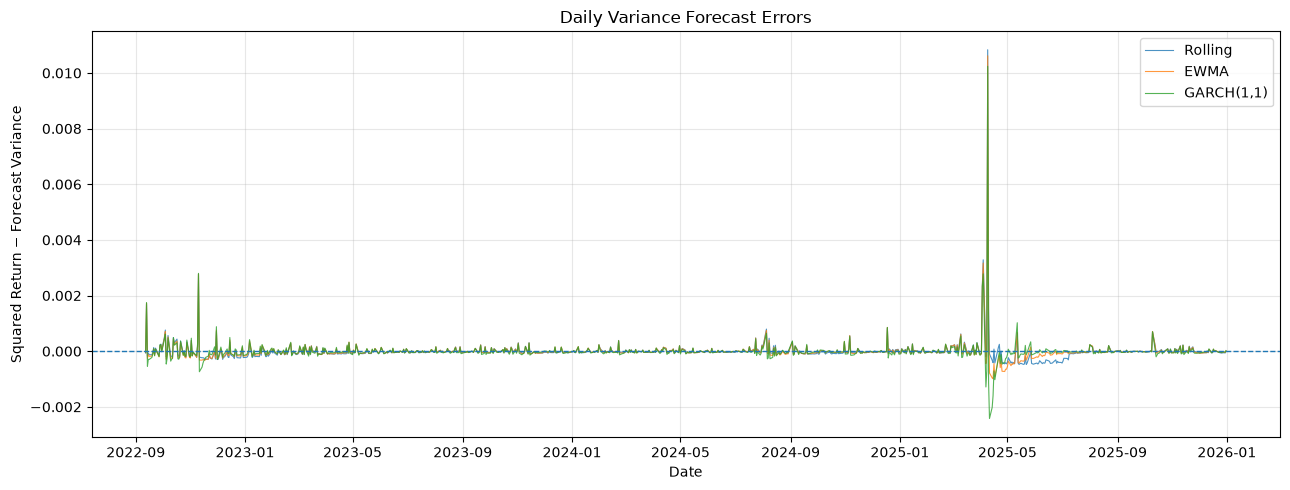

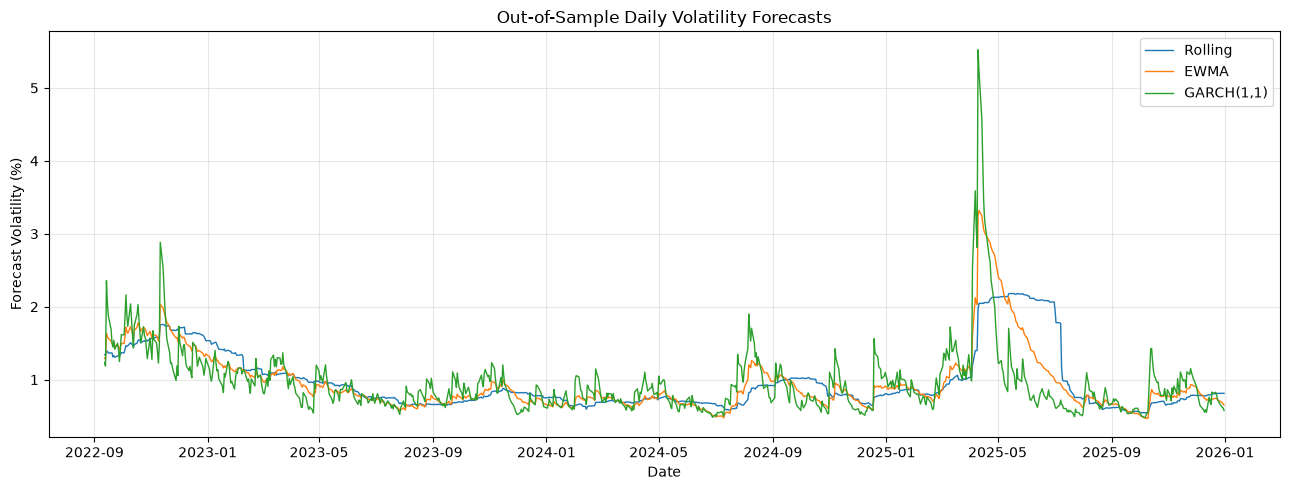

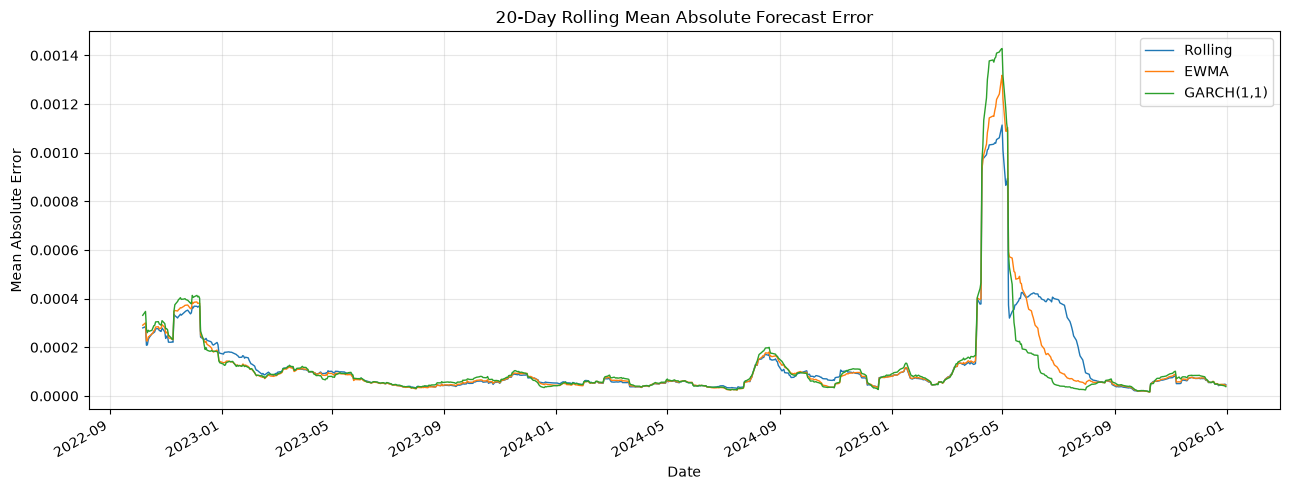

In [4]:
# Forecast error: variance proxy minus forecast variance.
forecast_errors = pd.DataFrame(
    {
        model: actual_variance_proxy - validation_data[column]
        for model, column in forecast_columns.items()
    },
    index=validation_data.index,
)

# Plot daily forecast errors.
plt.figure(figsize=(13, 5))

for model in forecast_errors.columns:
    plt.plot(
        forecast_errors.index,
        forecast_errors[model],
        label=model,
        linewidth=0.8,
        alpha=0.8,
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Daily Variance Forecast Errors")
plt.xlabel("Date")
plt.ylabel("Squared Return − Forecast Variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot forecast volatility, expressed as a percentage.
plt.figure(figsize=(13, 5))

for model, column in forecast_columns.items():
    plt.plot(
        validation_data.index,
        np.sqrt(validation_data[column]) * 100,
        label=model,
        linewidth=1,
    )

plt.title("Out-of-Sample Daily Volatility Forecasts")
plt.xlabel("Date")
plt.ylabel("Forecast Volatility (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Smoothed absolute forecast error helps compare error behavior.
rolling_abs_error = forecast_errors.abs().rolling(
    window=20,
    min_periods=20,
).mean()

rolling_abs_error.plot(figsize=(13, 5), linewidth=1)
plt.title("20-Day Rolling Mean Absolute Forecast Error")
plt.xlabel("Date")
plt.ylabel("Mean Absolute Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Forecast Error Analysis — Key Findings

Forecast errors are generally modest outside major market shocks, with a pronounced episode in April 2025. GARCH responds sharply to the large return movements and its forecast variance subsequently declines as the shocks fade. EWMA adjusts more smoothly, while rolling volatility responds more slowly and can remain elevated after the immediate shock has passed.

The results illustrate the trade-off between responsiveness and stability. They are consistent with the aggregate loss rankings, but do not independently establish statistical superiority. The next step examines whether the relative performance changes between calm and high-volatility conditions.

## 4. Performance Across Volatility Regimes

Model performance may differ between relatively calm and high-volatility conditions. We classify dates using the standard deviation of returns in a rolling 20-session window, shifted by one session so the regime indicator uses only prior returns. The code allows an initial estimate after at least five prior observations; therefore, the earliest valid labels can use fewer than 20 observations.

The bottom quartile represents calmer conditions and the top quartile represents higher-volatility conditions. The middle half of observations is excluded from this contrast. The regime labels are used only for retrospective evaluation; they are not inputs to the forecast models.

In [5]:
# Classify each date using only preceding returns.
trailing_volatility = (
    validation_data["Actual_Return"]
    .rolling(window=20, min_periods=5)
    .std()
    .shift(1)
)

regime_data = validation_data.loc[trailing_volatility.notna()].copy()
regime_volatility = trailing_volatility.loc[regime_data.index]

lower_cutoff = regime_volatility.quantile(0.25)
upper_cutoff = regime_volatility.quantile(0.75)

regime_data["Regime"] = np.select(
    [
        regime_volatility <= lower_cutoff,
        regime_volatility >= upper_cutoff,
    ],
    [
        "Calm",
        "High volatility",
    ],
    default="Middle",
)

# Calculate MSE and QLIKE separately for the two regimes.
regime_results = []

for regime in ["Calm", "High volatility"]:
    subset = regime_data.loc[regime_data["Regime"] == regime]
    actual_proxy = subset["Actual_Return"] ** 2

    for model, column in forecast_columns.items():
        forecast = subset[column]

        regime_results.append({
            "Regime": regime,
            "Model": model,
            "Observations": len(subset),
            "MSE": ((actual_proxy - forecast) ** 2).mean(),
            "QLIKE": (
                np.log(forecast) + actual_proxy / forecast
            ).mean(),
        })

regime_scores = pd.DataFrame(regime_results)

display(
    regime_scores.style.format({
        "MSE": "{:.6e}",
        "QLIKE": "{:.6f}",
    })
)

,Regime,Model,Observations,MSE,QLIKE
0,Calm,Rolling,207,1.393868e-08,-8.862293
1,Calm,EWMA,207,9.516805e-09,-8.856879
2,Calm,"GARCH(1,1)",207,9.285078e-09,-8.913380
3,High volatility,Rolling,207,7.558782e-07,-7.145862
4,High volatility,EWMA,207,7.387571e-07,-7.410968
5,High volatility,"GARCH(1,1)",207,7.416553e-07,-7.469236


### Regime Analysis — Key Findings

- In calmer conditions, GARCH(1,1) records the lowest MSE and QLIKE.
- In high-volatility conditions, EWMA records the lowest MSE, while GARCH(1,1) records the lowest QLIKE.
- Rolling volatility performs least favorably in the high-volatility regime under both metrics.
- These results suggest that model rankings depend on the loss function and market conditions.
- The regime comparisons are descriptive. Statistical testing is needed before drawing conclusions about whether loss differences are distinguishable from zero.

## 5. Statistical Comparison of Forecast Accuracy

We compare model pairs using a HAC-based Diebold–Mariano-style asymptotic test on MSE loss and QLIKE loss. The loss differential is the first model's loss minus the second model's loss; a negative average differential favors the first model.

The long-run variance uses a Newey–West HAC estimate, with five lags in the primary comparison. Pairwise p-values are adjusted using Holm's method separately within each metric. This is a DM-style asymptotic comparison without a separate small-sample correction.

The test results complement the loss rankings. Results are interpreted cautiously because daily volatility losses can be heavy-tailed and sensitive to extreme market movements.

In [6]:
from itertools import combinations
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# Build each model's loss series on the same evaluation dates.
losses = {}

for model, column in forecast_columns.items():
    forecast = validation_data[column]

    losses[(model, "MSE")] = forecast_errors[model] ** 2
    losses[(model, "QLIKE")] = (
        np.log(forecast) + actual_variance_proxy / forecast
    )


def dm_hac_test(loss_first, loss_second, max_lag=5):
    """DM-style test of equal mean loss using a Newey-West HAC estimate."""
    differential = (loss_first - loss_second).dropna().to_numpy()
    n = len(differential)

    if n <= max_lag + 1:
        raise ValueError("Insufficient observations for the selected HAC lag.")

    mean_diff = differential.mean()
    centered = differential - mean_diff

    # Newey-West estimate of the long-run variance of the loss differential.
    long_run_variance = np.dot(centered, centered) / n

    for lag in range(1, max_lag + 1):
        autocovariance = np.dot(
            centered[lag:],
            centered[:-lag],
        ) / n
        weight = 1 - lag / (max_lag + 1)
        long_run_variance += 2 * weight * autocovariance

    if long_run_variance <= 0:
        return mean_diff, np.nan, np.nan

    standard_error = np.sqrt(long_run_variance / n)
    statistic = mean_diff / standard_error
    p_value = 2 * norm.sf(abs(statistic))

    return mean_diff, statistic, p_value


dm_results = []

for metric in ["MSE", "QLIKE"]:
    for model_a, model_b in combinations(forecast_columns.keys(), 2):
        mean_diff, statistic, p_value = dm_hac_test(
            losses[(model_a, metric)],
            losses[(model_b, metric)],
            max_lag=5,
        )

        dm_results.append({
            "Metric": metric,
            "Model A": model_a,
            "Model B": model_b,
            "Mean Loss Difference (A - B)": mean_diff,
            "Test Statistic": statistic,
            "P-value": p_value,
        })

dm_results = pd.DataFrame(dm_results)

# Adjust for multiple pairwise comparisons within each metric.
dm_results["Holm-adjusted P-value"] = np.nan

for metric in dm_results["Metric"].unique():
    mask = dm_results["Metric"] == metric
    valid = dm_results.loc[mask, "P-value"].notna()

    adjusted = multipletests(
        dm_results.loc[mask].loc[valid, "P-value"],
        method="holm",
    )[1]

    dm_results.loc[dm_results.loc[mask].index[valid],
                   "Holm-adjusted P-value"] = adjusted

display(
    dm_results.style.format({
        "Mean Loss Difference (A - B)": "{:.6e}",
        "Test Statistic": "{:.3f}",
        "P-value": "{:.4f}",
        "Holm-adjusted P-value": "{:.4f}",
    })
)

,Metric,Model A,Model B,Mean Loss Difference (A - B),Test Statistic,P-value,Holm-adjusted P-value
0,MSE,Rolling,EWMA,7.668817e-09,1.042,0.2973,0.8920
1,MSE,Rolling,"GARCH(1,1)",6.430289e-09,0.427,0.6697,1.0000
2,MSE,EWMA,"GARCH(1,1)",-1.238529e-09,-0.118,0.9059,1.0000
3,QLIKE,Rolling,EWMA,9.003629e-02,1.777,0.0755,0.2266
4,QLIKE,Rolling,"GARCH(1,1)",1.190365e-01,1.718,0.0857,0.2266
5,QLIKE,EWMA,"GARCH(1,1)",2.900024e-02,1.052,0.2928,0.2928


### Statistical Comparison — Findings

- None of the pairwise loss differences is statistically significant at the 5% level after Holm adjustment.
- EWMA achieves the lowest overall MSE, while GARCH(1,1) achieves the lowest overall QLIKE.
- The QLIKE comparisons between rolling volatility and the two challenger models have raw p-values below 0.10, but neither remains significant after adjustment.
- The evidence therefore does not establish statistical superiority for any model. The observed rankings should be treated as descriptive rather than conclusive.

The tests use a HAC variance estimate with five lags and a normal approximation. Results should be interpreted cautiously given the sensitivity of volatility loss functions to extreme observations.

## 6. Model Strengths, Weaknesses and Sensitivity

This section first checks whether pairwise test conclusions are sensitive to the HAC lag specification, then summarizes the practical strengths and weaknesses of each forecasting approach. Rankings can depend on the loss function and may be affected by extreme observations.

### HAC Lag Sensitivity

In [7]:
sensitivity_results = []

for hac_lag in [5, 10, 20]:
    for metric in ["MSE", "QLIKE"]:
        for model_a, model_b in combinations(forecast_columns.keys(), 2):
            mean_diff, statistic, p_value = dm_hac_test(
                losses[(model_a, metric)],
                losses[(model_b, metric)],
                max_lag=hac_lag,
            )

            sensitivity_results.append({
                "HAC Lags": hac_lag,
                "Metric": metric,
                "Model A": model_a,
                "Model B": model_b,
                "Mean Loss Difference (A - B)": mean_diff,
                "Test Statistic": statistic,
                "P-value": p_value,
            })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(
    sensitivity_table.style.format({
        "Mean Loss Difference (A - B)": "{:.6e}",
        "Test Statistic": "{:.3f}",
        "P-value": "{:.4f}",
    })
)

,HAC Lags,Metric,Model A,Model B,Mean Loss Difference (A - B),Test Statistic,P-value
0,5,MSE,Rolling,EWMA,7.668817e-09,1.042,0.2973
1,5,MSE,Rolling,"GARCH(1,1)",6.430289e-09,0.427,0.6697
2,5,MSE,EWMA,"GARCH(1,1)",-1.238529e-09,-0.118,0.9059
3,5,QLIKE,Rolling,EWMA,9.003629e-02,1.777,0.0755
4,5,QLIKE,Rolling,"GARCH(1,1)",1.190365e-01,1.718,0.0857
5,5,QLIKE,EWMA,"GARCH(1,1)",2.900024e-02,1.052,0.2928
6,10,MSE,Rolling,EWMA,7.668817e-09,1.086,0.2775
7,10,MSE,Rolling,"GARCH(1,1)",6.430289e-09,0.548,0.5838
8,10,MSE,EWMA,"GARCH(1,1)",-1.238529e-09,-0.154,0.8775
9,10,QLIKE,Rolling,EWMA,9.003629e-02,1.673,0.0942


### Sensitivity Findings

- All unadjusted pairwise p-values remain above 0.05 for HAC lag choices of 5, 10, and 20.
- MSE comparisons are clearly nonsignificant across these lag choices; QLIKE comparisons between rolling volatility and the challengers have raw p-values near 0.10.
- Holm-adjusted p-values for the primary five-lag comparison are also above 0.05. The sensitivity table reports unadjusted p-values.

### Model Strengths and Weaknesses

### Rolling Volatility
**Strengths:** Simple, transparent, and relatively smooth.

**Weaknesses:** Responds slowly to sudden changes and can remain elevated while older observations stay in the rolling window.

### EWMA
**Strengths:** Computationally efficient and responsive to recent shocks, with no separate model-estimation step required for this comparison.

**Weaknesses:** Performance depends on the decay parameter, and the model does not explicitly estimate a long-run variance level.

### GARCH(1,1)
**Strengths:** Explicitly models conditional variance persistence and achieved the lowest QLIKE in the overall test period and in both evaluated volatility regimes.

**Weaknesses:** Requires parameter estimation, relies on model assumptions, and produced sharp forecast changes around extreme market movements. Its lower QLIKE was not statistically distinguishable from the alternatives in the pairwise tests.

### Overall Assessment
EWMA achieved the lowest overall MSE, while GARCH(1,1) achieved the lowest overall QLIKE. Rankings varied slightly by volatility regime, and the differences were not statistically significant after multiple-comparison adjustment. No model can therefore be declared a clear statistical winner from this experiment.

## 7. Validation Report and Recommendation

### Objective

This validation compared rolling volatility, EWMA, and GARCH(1,1) forecasts using 830 out-of-sample daily SPY returns from September 2022 through December 2025. Performance was assessed using MSE on squared returns, QLIKE, regime-based evaluation, and HAC-based DM-style pairwise forecast-loss comparisons.

### Key Findings

**Overall forecast accuracy**

- EWMA achieved the lowest MSE of \(1.9529\times10^{-7}\), narrowly ahead of GARCH(1,1) at \(1.9653\times10^{-7}\).
- GARCH(1,1) achieved the lowest QLIKE of -8.3763, followed by EWMA at -8.3473.
- Rolling volatility recorded the highest loss under both metrics.

**Performance across volatility regimes**

- In calmer conditions, GARCH(1,1) achieved the lowest MSE and QLIKE.
- In high-volatility conditions, EWMA achieved the lowest MSE, while GARCH(1,1) retained the lowest QLIKE.
- The relative ranking therefore depends on both the loss function and volatility regime.

**Statistical evidence**

- None of the pairwise comparisons was statistically significant after Holm adjustment at the 5% level.
- Unadjusted pairwise p-values remained above 0.05 across HAC lag choices of 5, 10, and 20; the primary Holm-adjusted tests were also nonsignificant.
- The observed differences in average forecast loss are not sufficient to establish that one model is statistically superior.

### Recommendation

**Retain EWMA as the primary benchmark and keep GARCH(1,1) as a challenger.**

EWMA is a reasonable operational default because it achieved the lowest overall MSE and is computationally simple. GARCH(1,1) should remain in the model comparison because it achieved the lowest QLIKE and performed well in the regime analysis.

The evidence does not justify replacing EWMA with GARCH solely on forecast accuracy grounds. Rolling volatility remains a useful transparent reference, but it ranked last on both overall loss metrics in this experiment.

### Limitations

- Squared daily returns are a noisy proxy for unobserved daily variance.
- The results are specific to SPY and the selected 2022–2025 test period.
- Extreme market movements have a substantial influence on forecast losses.
- Regime analysis covers the bottom and top quartiles of trailing volatility; the middle half was excluded from that comparison.
- The statistical tests depend on the loss function and HAC specification and do not prove that the models are equivalent.
- Results under a different market, evaluation period, forecast horizon, or volatility specification may differ.

### Final Conclusion

The experiment demonstrates that model ranking is sensitive to the evaluation metric and market conditions. EWMA has a slight advantage under overall MSE, while GARCH(1,1) performs better under QLIKE. Since the pairwise differences are not statistically significant after adjustment, the appropriate decision is to retain EWMA as the practical benchmark and continue evaluating GARCH as a challenger rather than declare a definitive winner.